# Лекция 4 - MLOps: исправленная и комментированная версия

> **Что изменено в этой версии**
>
> Исходные пояснения преподавателя сохранены. Код адаптирован под актуальный стек:
> Python 3.13, современный pandas и Great Expectations 1.23.x.
>
> Дополнительно добавлены комментарии к тем местам, где исходный лекционный код:
> - использовал устаревший API;
> - зависел от локального абсолютного пути;
> - мог приводить к утечке целевой переменной (`target leakage`);
> - демонстрировал упрощенную MLOps-логику, которую важно отличать от production-реализации.
>
> Блоки **«Дополнение»** ниже - пояснения к лекции, а не замена материала преподавателя.

Для запуска основной части нужны `pandas`, `numpy`, `tqdm`, `scikit-learn`,
`scipy`, `matplotlib`, `joblib`, `great-expectations`.

`D-Tale` и `ydata-profiling` используются как **опциональные** инструменты EDA:
если они не установлены, ноутбук продолжит выполняться.


In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
from tqdm import tqdm

warnings.filterwarnings("default")

print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")

pandas: 2.3.3
numpy: 2.3.5


### Дополнение: почему сначала определяем окружение

В MLOps воспроизводимость начинается с окружения: версии Python и библиотек влияют
на API, сериализацию моделей и даже на численные результаты. Поэтому полезно явно
видеть версии основных зависимостей уже в начале ноутбука.


Данные можно скачать с [kaggle](https://www.kaggle.com/datasets/wordsforthewise/lending-club?spm=a2ty_o01.29997173.0.0.532fc921UIOjfa).

Так как датасет содержит `2 260 701` наблюдений, это делает его весьма тяжелым для демонстрации функционала, снизим его до 20% наблюдений от изначального.

In [2]:
DATA_FILENAME = "accepted_2007_to_2018Q4.csv"

# Ноутбук может запускаться как из каталога lesson_4, так и из корня проекта.
# Поэтому проверяем несколько ожидаемых расположений относительно cwd и его родителей.
candidate_paths = []
for base in [Path.cwd(), *Path.cwd().parents]:
    candidate_paths.extend([
        base / "data" / DATA_FILENAME,
        base / "ci_cd" / "lesson_4" / "data" / DATA_FILENAME,
        base / "homework_tasks" / "ci_cd" / "lesson_4" / "data" / DATA_FILENAME,
    ])

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    checked = "\n".join(f"  - {p}" for p in candidate_paths[:12])
    raise FileNotFoundError(
        f"Не найден файл {DATA_FILENAME}.\n"
        f"Положите его в каталог data рядом с ноутбуком "
        f"или в homework_tasks/ci_cd/lesson_4/data.\n"
        f"Первые проверенные пути:\n{checked}"
    )

print(f"Датасет: {data_path}")

# df_full - полный исходный датасет.
# low_memory=False убирает DtypeWarning при чтении колонок со смешанными типами.
df_full = pd.read_csv(data_path, low_memory=False)

# df - рабочая 20%-я подвыборка для лекции.
# random_state нужен для воспроизводимости.
df = df_full.sample(frac=0.2, random_state=42).copy()

print(f"Размер полного датасета: {df_full.shape}")
print(f"Размер рабочей подвыборки: {df.shape}")
df.info()

Датасет: /Users/pontigor/python_test/mephi_homework_tasks/homework_tasks/ci_cd/lesson_4/data/accepted_2007_to_2018Q4.csv
Размер полного датасета: (2260701, 151)
Размер рабочей подвыборки: (452140, 151)
<class 'pandas.core.frame.DataFrame'>
Index: 452140 entries, 392949 to 867240
Columns: 151 entries, id to settlement_term
dtypes: float64(113), object(38)
memory usage: 524.3+ MB


### Дополнение: `df_full` и `df`

В исходной версии переменная `df_sample` содержала **полный** датасет, а `df` -
20%-ю выборку. Это путало дальнейший анализ репрезентативности.

Здесь:
- `df_full` - исходные 100% данных;
- `df` - воспроизводимая 20%-я рабочая подвыборка.

Абсолютный путь `/Users/...` убран: ноутбук можно переносить между компьютерами.


### Дополнение: просмотр схемы данных

Перед автоматическими проверками полезно явно посмотреть набор признаков:
так мы понимаем, какие поля являются идентификаторами, какие могут быть target,
а какие появились только после наступления события.

In [3]:
# Смотрим на то, какие признаки у нас есть в датасете
df.columns.tolist()

['id',
 'member_id',
 'loan_amnt',
 'funded_amnt',
 'funded_amnt_inv',
 'term',
 'int_rate',
 'installment',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'pymnt_plan',
 'url',
 'desc',
 'purpose',
 'title',
 'zip_code',
 'addr_state',
 'dti',
 'delinq_2yrs',
 'earliest_cr_line',
 'fico_range_low',
 'fico_range_high',
 'inq_last_6mths',
 'mths_since_last_delinq',
 'mths_since_last_record',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'initial_list_status',
 'out_prncp',
 'out_prncp_inv',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_prncp',
 'total_rec_int',
 'total_rec_late_fee',
 'recoveries',
 'collection_recovery_fee',
 'last_pymnt_d',
 'last_pymnt_amnt',
 'next_pymnt_d',
 'last_credit_pull_d',
 'last_fico_range_high',
 'last_fico_range_low',
 'collections_12_mths_ex_med',
 'mths_since_last_major_derog',
 'policy_code',
 'application_type',
 'annual_inc_joint',
 '

# Проведем анализ репрезентативности

**Цель анализа**

Убедиться, что случайно выбранная подвыборка (в данном случае 20% от исходных данных) адекватно отражает структуру и распределения полной выборки. Это необходимо для того, чтобы выводы, сделанные на основе подвыборки, были обобщаемыми и ненесмещенными.

**Проверка числовых признаков**

**Что анализируется?**

Для каждого числового признака сравниваются:

- Среднее значение в полной выборке.
- Среднее значение в подвыборке.
- Относительное отклонение между ними.

| Отклонение среднего | Оценка |
|---------------------|--------|
| `< 2%` | Хорошо |
| `2–5%` | Удовлетворительно |
| `> 5%` | Тревожно |

### Дополнение: что проверяет сравнение средних

Для числовых признаков здесь используется простой эвристический индикатор:
насколько среднее в 20%-й выборке отличается от среднего по полному датасету.
Это удобно для демонстрации, но не является строгим доказательством
репрезентативности. Для более глубокого анализа используют распределения,
доверительные интервалы и статистические тесты.

In [4]:
# Определим данные
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Исключим сразу ненужные столбцы (ид)
exclude_cols = ['id', 'member_id', 'issue_d']
numeric_cols = [col for col in numeric_cols if col not in exclude_cols]
categorical_cols = [col for col in categorical_cols if col not in exclude_cols]

# Сформируем отчет по числовым признакам
report_numeric = []
for col in numeric_cols:
    full_mean = df_full[col].mean()
    sample_mean = df[col].mean()
    
    # Избегаем деления на ноль или NaN
    if pd.isna(full_mean) or full_mean == 0:
        diff_percent = float('nan')
        status = "Не применимо"
    else:
        diff_percent = abs(full_mean - sample_mean) / abs(full_mean) * 100
        if diff_percent < 2:
            status = "Хорошо"
        elif diff_percent < 5:
            status = "Удовлетворительно"
        else:
            status = "Тревожно"

    report_numeric.append({
        'Признак': col,
        'Среднее (полная)': full_mean,
        'Среднее (подвыборка)': sample_mean,
        'Абсолютное отклонение': abs(full_mean - sample_mean),
        'Относительное отклонение (%)': diff_percent,
        'Оценка': status
    })

# Преобразуем в DataFrame
report_numeric = pd.DataFrame(report_numeric).round(4)

# Цветовая стилизация
def color_status(val):
    if val == "Хорошо":
        return "background-color: #d4edda"
    elif val == "Удовлетворительно":
        return "background-color: #fff3cd"
    elif val == "Тревожно":
        return "background-color: #f8d7da"
    return ""

print("ОТЧЕТ ПО ЧИСЛОВЫМ ПРИЗНАКАМ")
styled_numeric = report_numeric.style.map(color_status, subset=['Оценка'])
display(styled_numeric)

# Проведем итоговую оценку по числовым признакам
total_numeric = len(report_numeric)
good_numeric = len(report_numeric[report_numeric['Оценка'] == "Хорошо"])
warning_numeric = len(report_numeric[report_numeric['Оценка'] == "Удовлетворительно"])
bad_numeric = len(report_numeric[report_numeric['Оценка'] == "Тревожно"])

print(f"Числовые признаки: {total_numeric} всего")
print(f"Хорошо: {good_numeric}")
print(f"Удовлетворительно: {warning_numeric}")
print(f"Тревожно: {bad_numeric}")

# Новая логика на основе преобладания
if good_numeric > warning_numeric and good_numeric > bad_numeric:
    verdict_numeric = "Выборка репрезентативна: большинство числовых признаков в норме."
elif warning_numeric > good_numeric and warning_numeric > bad_numeric:
    verdict_numeric = "В целом выборка репрезентативна, но есть признаки с умеренными отклонениями."
elif bad_numeric > good_numeric and bad_numeric > warning_numeric:
    verdict_numeric = "Выборка не репрезентативна. Значительные искажения: преобладают крупные отклонения."
else:
    verdict_numeric = "Выборка неоднозначна: распределение оценок сбалансировано."

print(verdict_numeric)

ОТЧЁТ ПО ЧИСЛОВЫМ ПРИЗНАКАМ


,Признак,Среднее (полная),Среднее (подвыборка),Абсолютное отклонение,Относительное отклонение (%),Оценка
0,loan_amnt,15046.931200,15038.632800,8.298400,0.055100,Хорошо
1,funded_amnt,15041.664100,15033.657800,8.006300,0.053200,Хорошо
2,funded_amnt_inv,15023.437700,15015.775100,7.662600,0.051000,Хорошо
3,int_rate,13.092800,13.089100,0.003700,0.028300,Хорошо
4,installment,445.806800,445.674600,0.132200,0.029700,Хорошо
5,annual_inc,77992.428700,77918.871400,73.557300,0.094300,Хорошо
6,dti,18.824200,18.846600,0.022400,0.118900,Хорошо
7,delinq_2yrs,0.306900,0.307900,0.001000,0.321000,Хорошо
8,fico_range_low,698.588200,698.603700,0.015500,0.002200,Хорошо
9,fico_range_high,702.588400,702.603900,0.015500,0.002200,Хорошо


Числовые признаки: 112 всего
Хорошо: 108
Удовлетворительно: 2
Тревожно: 2
Выборка репрезентативна: большинство числовых признаков в норме.


**Проверка категориальных признаков**

**Что анализируется?**

Для каждого категориального признака сравниваются:

- Доли категорий в полной выборке.
- Доли категорий в подвыборке.
- Вычисляется среднее абсолютное отклонение долей по всем категориям.

| Отклонение долей | Оценка |
|------------------|--------|
| `< 1%` | Хорошо |
| `1–3%` | Удовлетворительно |
| `> 3%` | Тревожно |

In [5]:
# Сформируем отчет по категориальным признакам
report_categorical_summary = []
detailed_categorical_reports = {}  # Для детального анализа

for col in categorical_cols:
    full_dist = df_full[col].value_counts(normalize=True).sort_index()
    sample_dist = df[col].value_counts(normalize=True).sort_index()
    
    # Совместим индексы
    all_categories = full_dist.index.union(sample_dist.index)
    full_aligned = full_dist.reindex(all_categories, fill_value=0)
    sample_aligned = sample_dist.reindex(all_categories, fill_value=0)
    
    # Разница по каждой категории
    diff_per_cat = (sample_aligned - full_aligned).abs()
    mean_abs_diff = diff_per_cat.mean() * 100  # среднее отклонение в процентах
    
    # Оценка
    if mean_abs_diff < 1:
        status = "Хорошо"
    elif mean_abs_diff < 3:
        status = "Удовлетворительно"
    else:
        status = "Тревожно"

    report_categorical_summary.append({
        'Признак': col,
        'Среднее отклонение (%)': mean_abs_diff,
        'Кол-во категорий': len(all_categories),
        'Оценка': status
    })
    
    # Сохраняем детали
    detailed = pd.DataFrame({
        'Полная выборка': full_aligned.round(4),
        'Подвыборка': sample_aligned.round(4),
        'Разница (abs)': diff_per_cat.round(4)
    })
    detailed_categorical_reports[col] = detailed

# Преобразуем в DataFrame
report_categorical_summary = pd.DataFrame(report_categorical_summary).round(4)
report_categorical_summary = report_categorical_summary.sort_values(by='Среднее отклонение (%)')

# Стилизация категориальных
styled_categorical = report_categorical_summary.style.map(color_status, subset=['Оценка'])

print("\n\n ОТЧЕТ ПО КАТЕГОРИАЛЬНЫМ ПРИЗНАКАМ")
display(styled_categorical)

# Проведем итоговую оценку по категориальным признакам
total_cat = len(report_categorical_summary)
good_cat = len(report_categorical_summary[report_categorical_summary['Оценка'] == "Хорошо"])
warning_cat = len(report_categorical_summary[report_categorical_summary['Оценка'] == "Удовлетворительно"])
bad_cat = len(report_categorical_summary[report_categorical_summary['Оценка'] == "Тревожно"])

print(f"Категориальные признаки: {total_cat} всего")
print(f"Хорошо: {good_cat}")
print(f"Удовлетворительно: {warning_cat}")
print(f"Тревожно: {bad_cat}")

if good_cat > warning_cat and good_cat > bad_cat:
    verdict_categorical = "Выборка репрезентативна: большинство категориальных признаков в норме."
elif warning_cat > good_cat and warning_cat > bad_cat:
    verdict_categorical = "В целом выборка репрезентативна, но есть признаки с умеренными отклонениями."
elif bad_cat > good_cat and bad_cat > warning_cat:
    verdict_categorical = "Выборка не репрезентативна. Значительные искажения: преобладают крупные отклонения."
else:
    verdict_categorical = "Выборка неоднозначна: распределение оценок сбалансировано."

print(verdict_categorical)



 ОТЧЕТ ПО КАТЕГОРИАЛЬНЫМ ПРИЗНАКАМ


,Признак,Среднее отклонение (%),Кол-во категорий,Оценка
24,hardship_type,0.000000,1,Хорошо
20,application_type,0.000000,2,Хорошо
9,url,0.000100,2260668,Хорошо
12,title,0.000100,63154,Хорошо
3,emp_title,0.000100,512694,Хорошо
18,next_pymnt_d,0.000900,106,Хорошо
10,desc,0.001300,124500,Хорошо
23,hardship_flag,0.002100,2,Хорошо
8,pymnt_plan,0.002200,2,Хорошо
13,zip_code,0.002700,956,Хорошо


Категориальные признаки: 36 всего
Хорошо: 35
Удовлетворительно: 1
Тревожно: 0
Выборка репрезентативна: большинство категориальных признаков в норме.


In [6]:
# Финальный отчет на основе преобладания
print("\n" + "="*60)
print("ФИНАЛЬНЫЙ ОТЧЕТ")
print("="*60)

# Общее количество по оценкам (числовые + категориальные)
total_good = good_numeric + good_cat
total_warning = warning_numeric + warning_cat
total_bad = bad_numeric + bad_cat
total_all = total_good + total_warning + total_bad

# Проценты
pct_good = total_good / total_all * 100 if total_all > 0 else 0
pct_warning = total_warning / total_all * 100 if total_all > 0 else 0
pct_bad = total_bad / total_all * 100 if total_all > 0 else 0

print(f"Общая статистика по всем признакам:")
print(f"Хорошо: {total_good} ({pct_good:.1f}%)")
print(f"Удовлетворительно: {total_warning} ({pct_warning:.1f}%)")
print(f"Тревожно: {total_bad} ({pct_bad:.1f}%)")

# Определяем преобладающую оценку
if total_good > total_warning and total_good > total_bad:
    final_verdict = "Полная репрезентативность: большинство признаков имеют малые отклонения."
    explanation = "→ Подвыборка адекватно отражает полную выборку. Можно использовать для анализа."
elif total_warning > total_good and total_warning > total_bad:
    final_verdict = "Частичная репрезентативность: преобладают умеренные отклонения."
    explanation = "→ В целом приемлемо, но рекомендуется проверить выбросы или использовать стратификацию."
elif total_bad > total_good and total_bad > total_warning:
    final_verdict = "Низкая репрезентативность: значительная часть признаков сильно искажена."
    explanation = "→ Подвыборка неадекватна. Пересоздайте ее с стратификацией по ключевым признакам."
else:
    final_verdict = "**Неоднозначная репрезентативность**: нет четкого преобладания."
    explanation = "→ Распределение оценок сбалансировано. Рекомендуется анализ деталей."

print(f"\n{final_verdict}")
print(explanation)
print("="*60)


ФИНАЛЬНЫЙ ОТЧЕТ
Общая статистика по всем признакам:
Хорошо: 143 (96.6%)
Удовлетворительно: 3 (2.0%)
Тревожно: 2 (1.4%)

Полная репрезентативность: большинство признаков имеют малые отклонения.
→ Подвыборка адекватно отражает полную выборку. Можно использовать для анализа.


# Автоматическое тестирование данных с Great Expectations

### Дополнение: Great Expectations 1.23

В старых версиях GX часто встречался интерфейс `context.sources...` и работа через
`validator`. В GX 1.23 используется новый Fluent API:

`DataContext → DataSource → DataAsset → BatchDefinition → Batch → Expectation`.

`Batch` - конкретный набор данных, который мы валидируем.
`Expectation` - декларативное правило качества данных.


In [7]:
import great_expectations as gx

print(f"Great Expectations версия: {gx.__version__}")

# В GX 1.x DataFrame подключается через:
# Data Context -> Data Source -> Data Asset -> Batch Definition -> Batch.
context = gx.get_context()

DATA_SOURCE_NAME = "lending_club_pandas"
DATA_ASSET_NAME = "lending_club_dataframe"
BATCH_DEFINITION_NAME = "whole_dataframe"

# Код сделан идемпотентным: повторный запуск ячейки не создает дубликаты объектов.
try:
    data_source = context.data_sources.get(DATA_SOURCE_NAME)
except KeyError:
    data_source = context.data_sources.add_pandas(DATA_SOURCE_NAME)

try:
    data_asset = data_source.get_asset(DATA_ASSET_NAME)
except LookupError:
    data_asset = data_source.add_dataframe_asset(name=DATA_ASSET_NAME)

try:
    batch_definition = data_asset.get_batch_definition(BATCH_DEFINITION_NAME)
except KeyError:
    batch_definition = data_asset.add_batch_definition_whole_dataframe(
        BATCH_DEFINITION_NAME
    )

batch = batch_definition.get_batch(
    batch_parameters={"dataframe": df}
)

print(f"GX Batch создан для датасета размером: {df.shape}\n")

print("=" * 60)
print("Проверка 1: полнота")
print("=" * 60)
print("Ожидаем, что в важных для нас полях нет пропусков.\n")

critical_columns = [
    "loan_amnt",
    "annual_inc",
    "int_rate",
    "grade",
    "loan_status",
]

for col in critical_columns:
    if col not in df.columns:
        print(f"SKIP | {col:15} | столбец отсутствует")
        continue

    expectation = gx.expectations.ExpectColumnValuesToNotBeNull(
        column=col,
        meta={"dimension": "Completeness"},
    )
    result = batch.validate(expectation)
    status = "OK" if result.success else "FAIL"

    print(
        f"{status:4} | {col:15} | "
        f"пропусков: {df[col].isna().sum():,}"
    )

Great Expectations версия: 1.23.0
GX Batch создан для датасета размером: (452140, 151)

Проверка 1: полнота
Ожидаем, что в важных для нас полях нет пропусков.



Calculating Metrics: 100%|██████████| 8/8 [00:00<00:00, 1801.00it/s]


FAIL | loan_amnt       | пропусков: 6


Calculating Metrics: 100%|██████████| 8/8 [00:00<00:00, 1677.55it/s]


FAIL | annual_inc      | пропусков: 7


Calculating Metrics: 100%|██████████| 8/8 [00:00<00:00, 1717.39it/s]


FAIL | int_rate        | пропусков: 6


Calculating Metrics: 100%|██████████| 8/8 [00:00<00:00, 782.03it/s] 


FAIL | grade           | пропусков: 6


Calculating Metrics: 100%|██████████| 8/8 [00:00<00:00, 565.13it/s] 

FAIL | loan_status     | пропусков: 6


In [8]:
print("\n" + "=" * 60)
print("Проверка 2: Уникальность")
print("=" * 60)
print("Ожидаем, что ID кредитов уникальны.\n")

if "id" in df.columns:
    expectation = gx.expectations.ExpectColumnValuesToBeUnique(
        column="id",
        meta={"dimension": "Uniqueness"},
    )
    result = batch.validate(expectation)
    status = "OK" if result.success else "FAIL"

    print(
        f"{status} | id | "
        f"уникальных: {df['id'].nunique():,} / {len(df):,}"
    )
else:
    # loan_amnt + int_rate НЕ являются идентификатором займа, поэтому
    # не подменяем ими проверку уникальности.
    print("SKIP | столбец 'id' отсутствует - корректную проверку уникальности выполнить нельзя.")


Проверка 2: Уникальность
Ожидаем, что ID кредитов уникальны.



Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 18.13it/s] 

OK | id | уникальных: 452,140 / 452,140


In [9]:
print("\n" + "=" * 60)
print("Проверка 3: Согласованность")
print("=" * 60)
print("Ожидаем, что значения находятся в разумных бизнес-диапазонах.\n")

business_rules = {
    "loan_amnt": (1_000, 50_000),
    "annual_inc": (0, 1_000_000),
    "int_rate": (0, 35),
    "dti": (0, 100),
    "fico_range_low": (300, 850),
}

for col, (min_val, max_val) in business_rules.items():
    if col not in df.columns:
        print(f"SKIP | {col:15} | столбец отсутствует")
        continue

    expectation = gx.expectations.ExpectColumnValuesToBeBetween(
        column=col,
        min_value=min_val,
        max_value=max_val,
        meta={"dimension": "Consistency"},
    )
    result = batch.validate(expectation)
    status = "OK" if result.success else "FAIL"

    actual_min = df[col].min()
    actual_max = df[col].max()

    print(
        f"{status:4} | {col:15} | "
        f"ожидание: [{min_val}, {max_val}] | "
        f"факт: [{actual_min:.2f}, {actual_max:.2f}]"
    )


Проверка 3: Согласованность
Ожидаем, что значения находятся в разумных бизнес-диапазонах.



Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 21.00it/s] 


FAIL | loan_amnt       | ожидание: [1000, 50000] | факт: [500.00, 40000.00]


Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 21.39it/s] 


FAIL | annual_inc      | ожидание: [0, 1000000] | факт: [0.00, 10999200.00]


Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 21.35it/s] 


OK   | int_rate        | ожидание: [0, 35] | факт: [5.31, 30.99]


Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 21.40it/s] 


FAIL | dti             | ожидание: [0, 100] | факт: [-1.00, 999.00]


Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 20.94it/s] 

OK   | fico_range_low  | ожидание: [300, 850] | факт: [630.00, 845.00]


In [10]:
print("\n" + "=" * 60)
print("Проверка 4: Валидность")
print("=" * 60)
print("Ожидаем, что категориальные поля содержат допустимые значения.\n")

if "grade" in df.columns:
    expectation = gx.expectations.ExpectColumnValuesToMatchRegex(
        column="grade",
        regex=r"^[A-G]$",
        meta={"dimension": "Validity"},
    )
    result = batch.validate(expectation)
    status = "OK" if result.success else "FAIL"
    print(
        f"{status} | grade | "
        f"фактические значения: {sorted(df['grade'].dropna().unique())}"
    )

if "term" in df.columns:
    expectation = gx.expectations.ExpectColumnValuesToBeInSet(
        column="term",
        value_set=[" 36 months", " 60 months", "36 months", "60 months"],
        meta={"dimension": "Validity"},
    )
    result = batch.validate(expectation)
    status = "OK" if result.success else "FAIL"
    print(
        f"{status} | term  | "
        f"фактические значения: {sorted(df['term'].dropna().unique())}"
    )


Проверка 4: Валидность
Ожидаем, что категориальные поля содержат допустимые значения.



Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 17.37it/s] 


OK | grade | фактические значения: ['A', 'B', 'C', 'D', 'E', 'F', 'G']


Calculating Metrics: 100%|██████████| 10/10 [00:00<00:00, 19.62it/s] 

OK | term  | фактические значения: [' 36 months', ' 60 months']


В итоге мы автоматизировали следующие проверки:
- `Полнота`: Критичные поля заполнены
- `Уникальность`: Дубликатов не обнаружено
- `Согласованность`: Значения в бизнес-диапазонах
- `Валидность`: Форматы данных корректны

Что это дает для автоматизации ML?
1. Мы можем запускать эти проверки АВТОМАТИЧЕСКИ при каждом обновлении данных встроив такие проверки в pipeline CI/CD
2. Если данные "сломались" - пайплайн остановится и не обучит модель на мусоре
3. Это основа Data Quality Gate в MLOps-пайплайне

# Exploratory Data Analysis

В качестве демонстрации одного из инструментов, мы будем использовать `D-Tale`. Работает исключительно с VPN.

In [11]:
try:
    import dtale
    import dtale.app as dtale_app
    DTALE_AVAILABLE = True
    print("D-Tale доступен.")
except ImportError:
    DTALE_AVAILABLE = False
    print(
        "D-Tale не установлен. Этот демонстрационный блок пропущен. "
        "При необходимости: poetry add dtale"
    )

D-Tale доступен.


In [12]:
if DTALE_AVAILABLE:
    # D-Tale запускает локальный веб-интерфейс для интерактивного EDA.
    d = dtale.show(
        df,
        host="127.0.0.1",
        port=40000,
        ignore_duplicate=True,
    )
    print("Откройте в браузере:")
    print(d.main_url())
else:
    print("D-Tale пропущен: пакет не установлен.")

Откройте в браузере:
http://127.0.0.1:40000/dtale/main/1
None


Если в jupyter notebook не отображается вывод, то мы можем воспользоваться `pandas-profiling`, но это чрезвычайно долго, с таким размером датасета `452140, 151`. Давайте сократим его еще больше для `EDA`.

In [13]:
try:
    from ydata_profiling import ProfileReport
    YDATA_PROFILING_AVAILABLE = True
    print("ydata-profiling доступен.")
except ImportError:
    YDATA_PROFILING_AVAILABLE = False
    print(
        "ydata-profiling не установлен. Блок отчета пропущен. "
        "При необходимости: poetry add ydata-profiling"
    )

ydata-profiling не установлен. Блок отчёта пропущен. При необходимости: poetry add ydata-profiling


In [14]:
# Профилирование полного набора 452k x 151 может занимать много времени и памяти.
# Для учебной демонстрации берем ограниченную воспроизводимую выборку.
eda_sample = df.sample(
    n=min(20_000, len(df)),
    random_state=42,
)

if YDATA_PROFILING_AVAILABLE:
    profile = ProfileReport(
        eda_sample,
        title="EDA Report",
        minimal=True,
    )
    profile.to_file("eda_report.html")
    print("Отчет сохранен в eda_report.html")
else:
    print("Профилирование пропущено.")

Профилирование пропущено.


Сликшом долгая работа, попробуем свой кастомный скрипт

## Небольшая предобработка в начале!

# Мы предполагаем, что наша целевая переменная это `loan_status`

In [15]:
# Посмотрим подробнее, какие значения в этом столбце есть
df.loan_status.unique()

array(['Current', 'Fully Paid', 'Charged Off', 'Late (31-120 days)',
       'Late (16-30 days)', 'In Grace Period',
       'Does not meet the credit policy. Status:Fully Paid',
       'Does not meet the credit policy. Status:Charged Off', nan,
       'Default'], dtype=object)

Давайте проверим наше предположение

In [16]:
def find_target_column(df):
    """
    Функция автоматически находит столбец с целевой переменной (например, статус кредита).
    Ищет по названию, нормализуя его: убирает пробелы, регистр, знаки препинания.
    """

    # Нормализуем названия всех столбцов: приводим к нижнему регистру и удаляем все, кроме букв и цифр
    norm = {c: re.sub(r'[^a-z0-9]+', '', c.lower()) for c in df.columns}
    
    # Список ожидаемых имен целевой переменной (в нормализованном виде)
    preferred = [
        'loancondition', 'loan_status', 'loanstatus', 'isdefault', 'default',
        'badloan', 'chargedoff', 'defaulter', 'target', 'y'
    ]
    
    # 1) Проверяем точное совпадение с одним из предпочтительных имен
    for want in preferred:
        for c, cn in norm.items():
            if cn == want:
                return c  # Возвращаем оригинальное имя столбца
    
    # 2) Если не нашли - ищем столбцы, содержащие ключевые слова
    for c, cn in norm.items():
        if any(k in cn for k in ['default', 'charg', 'loanstatus', 'badloan', 'loancondition']):
            return c  # Например, 'chargedoff' или 'is_default'
    
    # 3) Если ничего не найдено - возвращаем первый бинарный столбец (ровно 2 уникальных значения)
    for c in df.columns:
        if df[c].dropna().nunique() == 2:  # Только 2 значения (например, 0/1, Да/Нет)
            return c
    
    # Если ничего не подошло - возвращаем None
    return None


def summarize_binary(df, col, mapping=None, keep_na=True):
    """
    Подсчитывает распределение значений в бинарном столбце и делает красивый вывод.
    Автоматически конвертирует строки в числа (например, 'Fully Paid' → 0).
    """
    s = df[col]  # Выбираем столбец
    
    # Если столбец строковый - пытаемся преобразовать в числа
    if s.dtype == object:
        # Заменяем строки на 0 и 1
        s = s.replace({
            '0': 0, '1': 1,
            'True': 1, 'False': 0,
            'true': 1, 'false': 0
        })
        
        # Конвертируем типичные кредитные статусы
        s = s.replace({
            'Fully Paid': 0,     # Полностью погашен → хороший заем
            'Current': 0,        # Текущий (но мы потом отфильтруем)
            'Good Loan': 0,      # Хороший заем
            'No Default': 0,     # Нет дефолта
            'Charged Off': 1,    # Списан как убыток → плохой заем
            'Default': 1,        # Дефолт
            'Bad Loan': 1        # Плохой заем
        })
    
    # Считаем количество каждого значения (включая NaN, если нужно)
    vc = s.value_counts(dropna=not keep_na)
    
    # Формируем таблицу с результатами
    out = vc.rename_axis('target').reset_index(name='Количество')
    out['Процент'] = (out['Количество'] / out['Количество'].sum() * 100).round(2)
    
    # Если передано отображение (mapping), заменяем числа на понятные метки
    if mapping is not None:
        out['target'] = out['target'].map(mapping).fillna(out['target'])
    
    return out


# Выводим размер датасета
print(f"Финальный датасет содержит {df.shape[0]} строк и {df.shape[1]} столбцов.\n")

# Ищем целевую переменную (столбец с информацией о дефолте)
target_col = find_target_column(df)

# Если не нашли - ошибка
if target_col is None:
    raise ValueError("Не удалось найти целевой столбец. Проверьте этапы предобработки данных.")

# Сообщаем, какой столбец выбран как целевой
print(f"Используется целевой столбец: {target_col}")

# Анализируем распределение значений в целевом столбце
summary = summarize_binary(
    df, 
    target_col,
    keep_na=True  # Сохраняем NaN в выводе
)

# Выводим распределение
print("\n Распределение статусов займов:\n")
print(summary.to_string(index=False))

Финальный датасет содержит 452140 строк и 151 столбцов.

Используется целевой столбец: loan_status

 Распределение статусов займов:

                                             target  Количество  Процент
                                                  0      390657    86.40
                                                  1       53995    11.94
                                 Late (31-120 days)        4379     0.97
                                    In Grace Period        1713     0.38
                                  Late (16-30 days)         859     0.19
 Does not meet the credit policy. Status:Fully Paid         373     0.08
Does not meet the credit policy. Status:Charged Off         158     0.03
                                                NaN           6     0.00


In [17]:
# Удаляем строки, где целевой статус отсутствует.
# Используем copy(), чтобы дальнейшие изменения не затрагивали исходную выборку неявно.
before = len(df)
df = df.dropna(subset=["loan_status"]).copy()
print(f"Удалено строк без loan_status: {before - len(df):,}")
print(f"Осталось строк: {len(df):,}")

Удалено строк без loan_status: 6
Осталось строк: 452,134


Перенесем наш таргет в бинарник по правилам:

- `Fully Paid` → `0`;
- `Does not meet the credit policy. Status:Fully Paid` → `0`;
- `Charged Off` → `1`;
- `Default` → `1`;
- `Late (31-120 days)` → `1`;
- `Late (16-30 days)` → `1`;
- `In Grace Period` → `1`;
- `Does not meet the credit policy. Status:Charged Off` → `1`.

### Дополнение

`Current` не является завершенным исходом кредита: такой займ еще нельзя честно
назвать ни погашенным, ни дефолтным. Поэтому в исправленной версии незавершенные
и неизвестные статусы **не принудительно превращаются в 0 или 1**, а исключаются
из обучающей выборки. Это уменьшает риск ошибки в целевой переменной.


In [18]:
df_clean = df.copy()

GOOD_STATUSES = {
    "Fully Paid",
    "Does not meet the credit policy. Status:Fully Paid",
}

BAD_STATUSES = {
    "Charged Off",
    "Default",
    "Late (31-120 days)",
    "Late (16-30 days)",
    "In Grace Period",
    "Does not meet the credit policy. Status:Charged Off",
}

target_mapping = {
    **{status: 0 for status in GOOD_STATUSES},
    **{status: 1 for status in BAD_STATUSES},
}

df_clean["target"] = df_clean["loan_status"].map(target_mapping)

unresolved = (
    df_clean.loc[df_clean["target"].isna(), "loan_status"]
    .value_counts(dropna=False)
)

print("Статусы, исключаемые из обучения как незавершенные/неопределенные:")
display(unresolved.to_frame("Количество"))

# Для supervised learning оставляем только строки с однозначно известным target.
df_final = df_clean.dropna(subset=["target"]).copy()
df_final["target"] = df_final["target"].astype("int8")

print(f"Изначально строк после удаления пустого loan_status: {len(df_clean):,}")
print(f"Строк с однозначным target: {len(df_final):,}")

print("\nРаспределение целевой переменной:")
value_counts = df_final["target"].value_counts().sort_index()
for label, count in value_counts.items():
    status_name = "Хороший заем (0)" if label == 0 else "Плохой заем (1)"
    print(f"  {status_name}: {count:,}")

Статусы, исключаемые из обучения как незавершённые/неопределённые:


,Количество
loan_status,
Current,176017


Изначально строк после удаления пустого loan_status: 452,134
Строк с однозначным target: 276,117

Распределение целевой переменной:
  Хороший заем (0): 215,013
  Плохой заем (1): 61,104


Скачать можно этот [скрипт](https://github.com/NeKonnnn/Exploratory_Data_Analysis/blob/main/eda_script.py)

А посмотреть как его использовать можно в [репозитории](https://github.com/NeKonnnn/Exploratory_Data_Analysis/tree/main), а именно в [ноутбуке](https://github.com/NeKonnnn/Exploratory_Data_Analysis/blob/main/test_script.ipynb)

### Дополнение: внешний `eda_script.py`

Преподаватель использует собственный вспомогательный модуль `eda_script.py`.
Ссылка на него сохранена выше. Чтобы `Run All` не зависел от наличия этого файла,
в этой версии есть небольшой fallback-класс с теми функциями, которые реально
используются далее в лекции.


In [19]:
import warnings
warnings.filterwarnings("ignore")

try:
    from eda_script import EDAProcessor
    print("Используется EDAProcessor из eda_script.py (вариант преподавателя).")
    eda = EDAProcessor(df_final)
    EDA_PROCESSOR_AVAILABLE = True
except ImportError:
    EDA_PROCESSOR_AVAILABLE = False
    print(
        "eda_script.py не найден. Используем встроенный fallback, "
        "чтобы ноутбук оставался самодостаточным."
    )

    class EDAProcessor:
        """Минимальный self-contained аналог функций, используемых ниже."""

        def __init__(self, dataframe):
            self.df = dataframe

        def generate_eda_summary(self):
            summary = pd.DataFrame({
                "dtype": self.df.dtypes.astype(str),
                "missing_count": self.df.isna().sum(),
                "missing_pct": (self.df.isna().mean() * 100).round(2),
                "nunique": self.df.nunique(dropna=False),
            })

            duplicates = self.df[self.df.duplicated(keep=False)]
            duplicate_columns = []

            cols = list(self.df.columns)
            # Проверка дублирующихся столбцов потенциально дорогая,
            # но после 20%-го семплирования приемлема для учебного примера.
            for i, left in enumerate(cols):
                for right in cols[i + 1:]:
                    if self.df[left].equals(self.df[right]):
                        duplicate_columns.append((left, right))

            return {
                "summary": summary,
                "duplicate_count": int(self.df.duplicated().sum()),
                "duplicates": duplicates,
                "duplicate_columns": duplicate_columns,
            }

    eda = EDAProcessor(df_final)

eda_script.py не найден. Используем встроенный fallback, чтобы ноутбук оставался самодостаточным.


In [20]:
# 1. Сводная таблица пропусков
eda_summary = eda.generate_eda_summary()
# Вывод таблицы
pd.set_option('display.max_rows', None)
display(eda_summary['summary'])

# Вывод количества дубликатов строк
print(f"Всего дубликатов строк: {eda_summary['duplicate_count']}")

# Вывод самих дубликатов строк
if not eda_summary['duplicates'].empty:
    print("Дублированные строки:")
    display(eda_summary['duplicates'])
else:
    print("Дубликатов строк не найдено.")

# Вывод дублированных столбцов
if eda_summary['duplicate_columns']:
    print("Дублированные столбцы:")
    for col1, col2 in eda_summary['duplicate_columns']:
        print(f"- {col1} и {col2}")
else:
    print("Дублированных столбцов не найдено.")

,dtype,missing_count,missing_pct,nunique
id,object,0,0.00,276117
member_id,float64,276117,100.00,1
loan_amnt,float64,0,0.00,1472
funded_amnt,float64,0,0.00,1472
funded_amnt_inv,float64,0,0.00,3229
term,object,0,0.00,2
int_rate,float64,0,0.00,633
installment,float64,0,0.00,48608
grade,object,0,0.00,7
sub_grade,object,0,0.00,35


Всего дубликатов строк: 0
Дубликатов строк не найдено.
Дублированные столбцы:
- deferral_term и hardship_length


# Препроцессинг

## Удаляем ненужные столбцы

In [21]:
# 1. Удалим все столбцы, где больше 60% пропусков. 
# Порог для удаления: 60% пропусков
threshold = 0.6

# Вычисляем долю пропусков в каждом столбце
missing_ratio = df_final.isnull().mean()  # доля NaN по столбцам

# Создаем маску: True - если пропусков МЕНЬШЕ 60% (такие столбцы оставляем)
mask = missing_ratio < threshold

# Определяем, какие столбцы будут удалены
columns_to_drop = df_final.columns[~mask].tolist()

# Выводим информацию
print("Удаляются столбца >= 60% пропусков:\n")
if columns_to_drop:
    print(f"Количество удаляемых столбцов: {len(columns_to_drop)}")
    print("\nСписок удаленных столбцов:")
    for i, col in enumerate(columns_to_drop, 1):
        print(f"  {i:2d}. {col} - {missing_ratio[col]:.1%} пропусков")
else:
    print("Нет столбцов с ≥60% пропусков. Ничего не удаляется.")

# Применяем маску - удаляем "тяжелые" столбцы
df_final = df_final.loc[:, mask]

# Итог
print(f"\n Осталось столбцов: {df_final.shape[1]} из {len(missing_ratio)}")

Удаляются столбца >= 60% пропусков:

Количество удаляемых столбцов: 44

Список удалённых столбцов:
   1. member_id — 100.0% пропусков
   2. desc — 91.0% пропусков
   3. mths_since_last_record — 83.0% пропусков
   4. next_pymnt_d — 97.3% пропусков
   5. mths_since_last_major_derog — 73.5% пропусков
   6. annual_inc_joint — 97.9% пропусков
   7. dti_joint — 97.9% пропусков
   8. verification_status_joint — 97.9% пропусков
   9. il_util — 64.2% пропусков
  10. mths_since_recent_bc_dlq — 76.2% пропусков
  11. mths_since_recent_revol_delinq — 66.5% пропусков
  12. revol_bal_joint — 98.4% пропусков
  13. sec_app_fico_range_low — 98.4% пропусков
  14. sec_app_fico_range_high — 98.4% пропусков
  15. sec_app_earliest_cr_line — 98.4% пропусков
  16. sec_app_inq_last_6mths — 98.4% пропусков
  17. sec_app_mort_acc — 98.4% пропусков
  18. sec_app_open_acc — 98.4% пропусков
  19. sec_app_revol_util — 98.4% пропусков
  20. sec_app_open_act_il — 98.4% пропусков
  21. sec_app_num_rev_accts — 98.4% проп

In [22]:
# Удаляем идентификаторы, технические и уже использованные целевые поля.
# errors="ignore" делает ячейку устойчивой, если какого-то столбца нет.
columns_to_drop = [
    "Unnamed: 0",
    "id",
    "member_id",
    "url",
    "policy_code",
    "loan_status",
]

df_final = df_final.drop(
    columns=columns_to_drop,
    errors="ignore",
)

df_final.shape

(276117, 104)

### Дополнение: защита от `target leakage`

Если задача - предсказывать риск **в момент выдачи кредита**, модель не должна
видеть информацию, появившуюся уже после выдачи: фактические платежи, взыскания,
остаток долга, settlement/hardship и т. п.

Иначе метрика на тесте может выглядеть очень высокой, но модель будет использовать
«информацию из будущего» и окажется бесполезной в реальном скоринге.


In [23]:
leakage_columns = [
    "out_prncp",
    "out_prncp_inv",
    "total_pymnt",
    "total_pymnt_inv",
    "total_rec_prncp",
    "total_rec_int",
    "total_rec_late_fee",
    "recoveries",
    "collection_recovery_fee",
    "last_pymnt_d",
    "last_pymnt_amnt",
    "next_pymnt_d",
    "last_credit_pull_d",
    "last_fico_range_high",
    "last_fico_range_low",
    "hardship_flag",
    "hardship_type",
    "hardship_reason",
    "hardship_status",
    "deferral_term",
    "hardship_amount",
    "hardship_start_date",
    "hardship_end_date",
    "payment_plan_start_date",
    "hardship_length",
    "hardship_dpd",
    "hardship_loan_status",
    "orig_projected_additional_accrued_interest",
    "hardship_payoff_balance_amount",
    "hardship_last_payment_amount",
    "debt_settlement_flag",
    "debt_settlement_flag_date",
    "settlement_status",
    "settlement_date",
    "settlement_amount",
    "settlement_percentage",
    "settlement_term",
]

present_leakage_columns = [
    col for col in leakage_columns
    if col in df_final.columns
]

df_final = df_final.drop(
    columns=present_leakage_columns,
    errors="ignore",
)

print(f"Удалено post-outcome / leakage-признаков: {len(present_leakage_columns)}")
print(f"Итоговый размер перед моделированием: {df_final.shape}")

Удалено post-outcome / leakage-признаков: 16
Итоговый размер перед моделированием: (276117, 88)


In [24]:
numeric_columns = df_final.select_dtypes(include=['number']).columns.tolist()
categorical_columns = df_final.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Кол-во числовых признаков :{len(numeric_columns)}")
print(f"Кол-во категориальных признаков :{len(categorical_columns)}")

Кол-во числовых признаков :71
Кол-во категориальных признаков :17


### Что еще в EDA мы можем сделать?

## Делим выборки:

In [25]:
from sklearn.model_selection import train_test_split

target_col = 'target'  
y = df_final[target_col]          # целевая переменная
X = df_final.drop(columns=[target_col])  # все остальные признаки

# Разделяем на train и test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,           # 20% на тест
    random_state=42,
    stratify=y               
)

Распределение статусов займов в обучающей и тестовой выборках:



,Выборка,Категория,Статус кредита,Количество,Процент
0,Обучающая,Хороший заем,0,172010,77.87
1,Обучающая,Плохой заем,1,48883,22.13
2,Тестовая,Хороший заем,0,43003,77.87
3,Тестовая,Плохой заем,1,12221,22.13


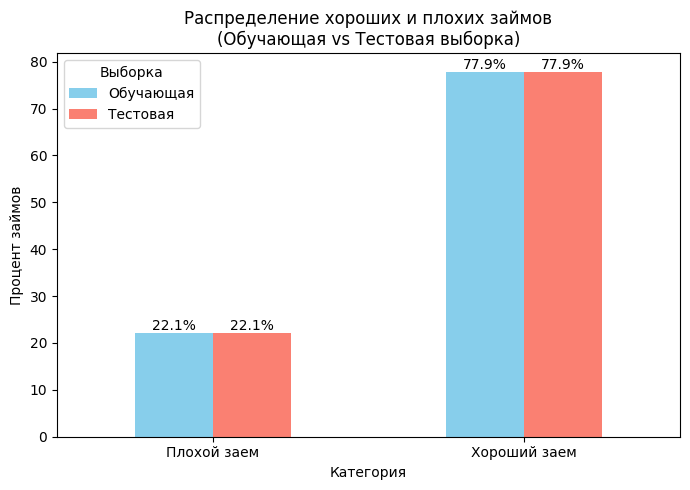

In [26]:
import matplotlib.pyplot as plt

# Анализ таргета
def summarize_target(y, label=""):
    """
    Создает таблицу с количеством и долей хороших и плохих займов.
    
    Параметры:
        y (pd.Series): Целевая переменная (0 = хороший заем, 1 = плохой)
        label (str): Название выборки (например, 'Train', 'Test')
    
    Возвращает:
        DataFrame с распределением по категориям
    """
    # Подсчитываем количество каждого класса (0 и 1)
    counts = y.value_counts().rename_axis("Статус кредита").reset_index(name="Количество")
    
    # Преобразуем числовые метки в понятные категории
    counts["Категория"] = counts["Статус кредита"].map({
        0: "Хороший заем",
        1: "Плохой заем"
    })
    
    # Вычисляем процент от общего числа
    counts["Процент"] = (counts["Количество"] / counts["Количество"].sum() * 100).round(2)
    
    # Добавляем столбец с названием выборки (Train / Test)
    counts.insert(0, "Выборка", label)
    
    # Возвращаем только нужные столбцы в удобном порядке
    return counts[["Выборка", "Категория", "Статус кредита", "Количество", "Процент"]]


# Применяем функцию к обучающей и тестовой выборкам
train_summary = summarize_target(y_train, "Обучающая")
test_summary  = summarize_target(y_test,  "Тестовая")

# Объединяем результаты в одну таблицу
summary_table = pd.concat([train_summary, test_summary], ignore_index=True)

# Выводим таблицу
print("Распределение статусов займов в обучающей и тестовой выборках:\n")
display(summary_table)


# График: сравнение распределений
fig, ax = plt.subplots(figsize=(7, 5))

# Преобразуем таблицу в сводную для визуализации: строки - категории, столбцы - выборки
summary_plot = summary_table.pivot(index="Категория", columns="Выборка", values="Процент")

# Строим столбчатую диаграмму
summary_plot.plot(
    kind="bar",
    ax=ax,
    rot=0,                    
    color=["skyblue", "salmon"]  
)

# Настройка графика
ax.set_ylabel("Процент займов")
ax.set_title("Распределение хороших и плохих займов\n(Обучающая vs Тестовая выборка)")

# Добавляем проценты над столбцами
for p in ax.patches:
    height = p.get_height()
    if not pd.isna(height):  # Проверяем, что значение не NaN
        ax.annotate(f"{height:.1f}%", 
                    (p.get_x() + p.get_width()/2., height), 
                    ha='center', va='bottom')  # По центру столбца, снизу

# Убираем лишние отступы
plt.tight_layout()

# Отображаем график
plt.show()

# Следующая итерация это Feature Engineering

Но его нет :( 

In [27]:
checkpoint_path = Path("checkpoint_df.csv")
df_final.to_csv(checkpoint_path, index=False)
print(f"Checkpoint сохранен: {checkpoint_path.resolve()}")

Checkpoint сохранён: /Users/pontigor/python_test/mephi_homework_tasks/homework_tasks/ci_cd/lesson_4/checkpoint_df.csv


In [28]:
df_final = pd.read_csv("checkpoint_df.csv", low_memory=False)
print(f"Checkpoint загружен: {df_final.shape}")

Checkpoint загружен: (276117, 88)


# Построение ML-модели

In [29]:
# Для ускорения учебного GridSearch используем 10% подготовленных данных.
# В production объем выборки выбирают исходя из времени обучения и требований к качеству.
model_df = df_final.sample(frac=0.1, random_state=42).copy()
print(f"Размер выборки для обучения моделей: {model_df.shape}")

Размер выборки для обучения моделей: (27612, 88)


In [30]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

import matplotlib.pyplot as plt
import numpy as np

### Топорная очистка от пропусков - ТАК НЕ ДЕЛАЙТЕ

In [31]:
# Определяем типы признаков до построения ColumnTransformer.
numeric_features = (
    model_df
    .drop(columns=["target"])
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)

categorical_features = (
    model_df
    .drop(columns=["target"])
    .select_dtypes(include=["object", "category"])
    .columns
    .tolist()
)

print(f"Числовые признаки ({len(numeric_features)}): {numeric_features[:5]}...")
print(f"Категориальные признаки ({len(categorical_features)}): {categorical_features[:5]}...")

Числовые признаки (70): ['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment']...
Категориальные признаки (17): ['term', 'grade', 'sub_grade', 'emp_title', 'emp_length']...


In [32]:
# В исходной лекции здесь была "топорная" ручная очистка.
# В исправленной версии DataFrame НЕ изменяем.
# Заполнение NaN будет частью sklearn Pipeline (см. SimpleImputer ниже).
print("Пропуски оставляем как есть до Pipeline.")
print(f"Всего NaN в model_df: {model_df.isna().sum().sum():,}")

Пропуски оставляем как есть до Pipeline.
Всего NaN в model_df: 278,849


In [33]:
# Наличие NaN на этом этапе ожидаемо и корректно.
# Важный MLOps-принцип: одинаковый preprocessing должен применяться
# и при fit(), и при predict(), поэтому он хранится внутри Pipeline.
missing_by_column = model_df.isna().sum()
missing_by_column = missing_by_column[missing_by_column > 0].sort_values(ascending=False)

print(f"Колонок с пропусками до Pipeline: {len(missing_by_column)}")
display(missing_by_column.head(10).to_frame("missing_count"))

Колонок с пропусками до Pipeline: 57


,missing_count
mths_since_rcnt_il,16531
all_util,16235
open_acc_6m,16233
open_rv_12m,16233
total_bal_il,16233
open_il_24m,16233
open_il_12m,16233
open_act_il,16233
open_rv_24m,16233
max_bal_bc,16233


In [34]:
target_col = "target"

y = model_df[target_col]
X = model_df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (22089, 87), Test: (5523, 87)


### 1. Создадим пайплайн препроцессинга

### Дополнение: почему `SimpleImputer` должен быть внутри `Pipeline`

Если заполнить пропуски **до** `train_test_split`, можно случайно использовать
статистики тестовой выборки при подготовке train - это разновидность leakage.

Когда `SimpleImputer` находится внутри `Pipeline`, его медианы/моды вычисляются
только во время `fit()` на train, а затем те же значения применяются на test и
на новых production-данных.


In [35]:
# Числовой pipeline:
# 1) медианная импутация пропусков;
# 2) стандартизация.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Категориальный pipeline:
# 1) наиболее частая категория вместо NaN;
# 2) One-Hot Encoding.
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
        ),
    ),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

print("Preprocessor сформирован.")

Preprocessor сформирован.


- drop='first' - избегаем мультиколлинеарности
- handle_unknown='ignore' - защита при предсказании

Что значит `handle_unknown`='ignore' - "защита при предсказании"?

Ситуация:

Мы обучили модель на данных, где категориальный признак home_ownership имеет значения: `RENT`, `OWN`, `MORTGAGE`

Но в тестовых или новых данных появляется значение, которого не было в обучении: `OTHER`

По умолчанию OneHotEncoder выдаст ошибку, потому что не знает, как его кодировать.

### 2. Сборка полного пайплайна

In [36]:
# Словарь моделей
models = {
    "Logistic Regression": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(random_state=42))
    ]) #,
    # "SVM": Pipeline([
    #     ('preprocessor', preprocessor),
    #     ('classifier', SVC(probability=True, random_state=42))
    # ])
}

### 3. Обучение и оценка моделей при помощи метрик качества

In [37]:
print("Столбцы в X_train:", X_train.shape[1])
print("Столбцы в X_test:", X_test.shape[1])
print("Совпадают:", list(X_train.columns) == list(X_test.columns))

Столбцы в X_train: 87
Столбцы в X_test: 87
Совпадают: True


In [38]:
results = {}

# Создаем прогресс-бар для итерации по моделям
for name, model in tqdm(models.items(), desc="Обучение моделей", unit="модель"):
    # Обучение с прогресс-баром
    print(f"\nОбучение {name}...")
    model.fit(X_train, y_train)
    
    # Предсказания
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    # Сохраняем метрики
    results[name] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba)
    }
    
    print(f"{name} завершен")

# Выводим результаты
print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ МОДЕЛЕЙ:")
print("="*50)

for model_name, metrics in results.items():
    print(f"\n{model_name}:")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value:.4f}")

Обучение моделей:   0%|          | 0/2 [00:00<?, ?модель/s]


Обучение Logistic Regression...


Обучение моделей:  50%|█████     | 1/2 [00:01<00:01,  1.17s/модель]

Logistic Regression завершён

Обучение Random Forest...


Обучение моделей: 100%|██████████| 2/2 [00:10<00:00,  5.39s/модель]

Random Forest завершён

РЕЗУЛЬТАТЫ МОДЕЛЕЙ:

Logistic Regression:
  accuracy: 0.7813
  precision: 0.5078
  recall: 0.1868
  f1: 0.2732
  roc_auc: 0.6997

Random Forest:
  accuracy: 0.7806
  precision: 0.5714
  recall: 0.0099
  f1: 0.0194
  roc_auc: 0.7053


In [39]:
results_df = pd.DataFrame(results).T
print("Сравнение моделей:")
print(results_df.round(3))

Сравнение моделей:
                     accuracy  precision  recall     f1  roc_auc
Logistic Regression     0.781      0.508   0.187  0.273    0.700
Random Forest           0.781      0.571   0.010  0.019    0.705


In [40]:
# Словари для хранения предсказаний
y_pred_dict = {}
y_proba_dict = {}

# Прогресс-бар для получения предсказаний
for name, model in tqdm(models.items(), desc="Получение предсказаний", unit="модель"):
    y_pred_dict[name] = model.predict(X_test)
    y_proba_dict[name] = model.predict_proba(X_test)[:, 1]

Получение предсказаний: 100%|██████████| 2/2 [00:00<00:00,  5.06модель/s]


Построение ROC-кривых: 100%|██████████| 2/2 [00:00<00:00, 254.19модель/s]


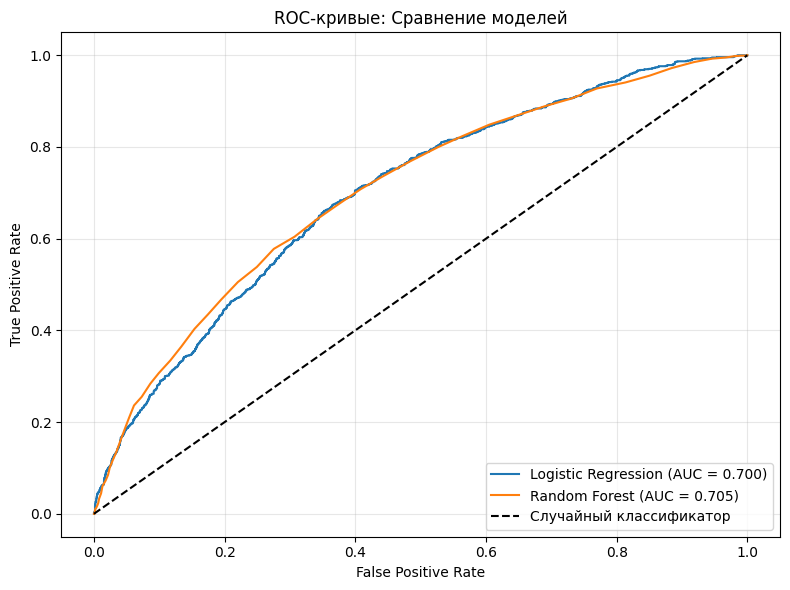

In [41]:
plt.figure(figsize=(8, 6))

# Прогресс-бар для построения ROC-кривых
model_names = list(y_proba_dict.keys())

for name in tqdm(model_names, desc="Построение ROC-кривых", unit="модель"):
    fpr, tpr, _ = roc_curve(y_test, y_proba_dict[name])
    auc = roc_auc_score(y_test, y_proba_dict[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Диагональ - случайный классификатор
plt.plot([0, 1], [0, 1], 'k--', label="Случайный классификатор")

# Оформление
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые: Сравнение моделей")
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Тюнинг гиперпараметров (GridSearchCV)

In [42]:
# Общий Pipeline: preprocessing + модель.
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

# Сетка включает не только гиперпараметры, но и выбор алгоритма.
# solver="liblinear" поддерживает и L1, и L2 penalty.
param_grid = [
    {
        "classifier": [
            LogisticRegression(
                max_iter=1000,
                solver="liblinear",
                random_state=42,
            )
        ],
        "classifier__C": [0.1, 1, 10],
        "classifier__penalty": ["l1", "l2"],
    },
    {
        "classifier": [RandomForestClassifier(random_state=42)],
        "classifier__n_estimators": [50, 100],
        "classifier__max_depth": [5, 10, None],
    },
]

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True,
)

grid_search.fit(X_train, y_train)

print("Лучшая модель:", grid_search.best_estimator_["classifier"].__class__.__name__)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший CV AUC:", round(grid_search.best_score_, 4))

test_proba = grid_search.best_estimator_.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))

Лучшая модель: LogisticRegression
Лучшие параметры: {'classifier': LogisticRegression(max_iter=1000, random_state=42, solver='liblinear'), 'classifier__C': 0.1, 'classifier__penalty': 'l1'}
Лучший CV AUC: 0.7199
Test ROC-AUC: 0.7153


In [43]:
import joblib

MODEL_PATH = Path("credit_scoring_model.pkl")

# Это локальный артефакт модели, а не полноценный Model Registry.
joblib.dump(grid_search.best_estimator_, MODEL_PATH)
print(f"Модель сохранена: {MODEL_PATH.resolve()}")

Модель сохранена: /Users/pontigor/python_test/mephi_homework_tasks/homework_tasks/ci_cd/lesson_4/credit_scoring_model.pkl


# Автоматизация и MLOps (Модель в продакшене)

### Дополнение: локальный файл ≠ Model Registry

`joblib.dump()` сохраняет модель как локальный артефакт. Это полезно для демонстрации
сериализации, но **Model Registry** обычно дополнительно хранит версии, стадии,
метаданные, связь с экспериментами и аудит изменений (например, MLflow Model Registry).


In [44]:
from scipy import stats

print("\nШаг 1: Загрузка локального артефакта модели")
pipeline_loaded = joblib.load(MODEL_PATH)
print("Модель успешно загружена в память.\n")


Шаг 1: Загрузка локального артефакта модели
Модель успешно загружена в память.



In [45]:
print("Шаг 2: Инференс модели на нескольких наблюдениях")

new_applications = X_test.head(5)

predictions = pipeline_loaded.predict(new_applications)
probabilities = pipeline_loaded.predict_proba(new_applications)[:, 1]

result_df = pd.DataFrame({
    "row_id": new_applications.index,
    "predicted_class": predictions,
    "probability_class_1": np.round(probabilities, 4),
})

print("\nРезультаты предсказаний:")
display(result_df)

# В реальной кредитной системе порог и бизнес-решение задаются отдельно:
# модель выдает score/probability, а не должна сама определять политику одобрения.

Шаг 2: Инференс модели на нескольких наблюдениях

Результаты предсказаний:


,row_id,predicted_class,probability_class_1
0,22893,0,0.3525
1,70986,0,0.2544
2,212032,0,0.2135
3,166183,0,0.1256
4,168004,0,0.2832


### Дополнение: что здесь является и не является Data Drift

Train/Test, полученные случайным разбиением одного исторического датасета,
**не моделируют настоящий временной drift**. Ячейка нужна, чтобы понять механику
двухвыборочного KS-теста.

В production обычно сравнивают:
- `reference` - данные периода обучения/валидации;
- `current` - новый поток или новый временной срез.

Сам по себе `p-value` также не является достаточным production-критерием.


In [46]:
print("Шаг 3: Демонстрационная проверка стабильности распределений")
print(
    "Для иллюстрации сравниваем Train и Test из одного исторического датасета.\n"
    "В production вместо Test здесь должен быть новый временной срез данных.\n"
)

numeric_cols_check = X_train.select_dtypes(include=[np.number]).columns[:5]

drift_detected = False
alpha = 0.05
drift_results = []

for col in numeric_cols_check:
    reference = X_train[col].dropna()
    current = X_test[col].dropna()

    ks_stat, p_value = stats.ks_2samp(reference, current)
    is_drift = p_value < alpha
    drift_detected |= is_drift

    drift_results.append({
        "feature": col,
        "ks_statistic": ks_stat,
        "p_value": p_value,
        "drift_flag": is_drift,
    })

drift_results_df = pd.DataFrame(drift_results)
display(drift_results_df)

print("\nВажно:")
print(
    "- p-value < 0.05 - статистический сигнал различия распределений;\n"
    "- на больших выборках даже небольшие различия могут быть статистически значимыми;\n"
    "- production drift-monitoring обычно дополняют effect-size/PSI и бизнес-порогами."
)

Шаг 3: Демонстрационная проверка стабильности распределений
Для иллюстрации сравниваем Train и Test из одного исторического датасета.
В production вместо Test здесь должен быть новый временной срез данных.



,feature,ks_statistic,p_value,drift_flag
0,loan_amnt,0.013483,0.394568,False
1,funded_amnt,0.013302,0.411378,False
2,funded_amnt_inv,0.013709,0.374087,False
3,int_rate,0.008640,0.893487,False
4,installment,0.010620,0.697297,False



Важно:
- p-value < 0.05 — статистический сигнал различия распределений;
- на больших выборках даже небольшие различия могут быть статистически значимыми;
- production drift-monitoring обычно дополняют effect-size/PSI и бизнес-порогами.


In [47]:
print("Шаг 4: Демонстрация логики триггера переобучения")

if drift_detected:
    print("Сформирован сигнал на запуск training pipeline.")
    print("В production следующим шагом могли бы быть:")
    print("1. Сбор и валидация нового датасета.")
    print("2. Обучение кандидата.")
    print("3. Сравнение кандидата с текущей моделью.")
    print("4. Регистрация новой версии при прохождении quality gates.")
    print("5. Отдельный deployment-процесс.")
else:
    print("Сигнал переобучения не сформирован.")

print(
    "\nЭта ячейка не выполняет реальный retraining/deployment - "
    "она показывает orchestration-логику."
)

Шаг 4: Демонстрация логики триггера переобучения
Сигнал переобучения не сформирован.

Эта ячейка не выполняет реальный retraining/deployment — она показывает orchestration-логику.


# Итоги

Мы прошли учебный путь:

1. Загрузили данные и проверили репрезентативность рабочей подвыборки.
2. Протестировали качество данных через Great Expectations.
3. Провели EDA и базовый препроцессинг.
4. Сформировали целевую переменную и обсудили риск `target leakage`.
5. Собрали preprocessing и модель в единый `scikit-learn Pipeline`.
6. Сравнили модели и выполнили `GridSearchCV`.
7. Сохранили и загрузили локальный артефакт модели.
8. Разобрали принцип drift-check и условного retraining-триггера.

### Что из этого уже похоже на MLOps

- воспроизводимая загрузка/подготовка данных;
- Data Quality checks;
- единый preprocessing + model pipeline;
- сериализация модели;
- автоматизируемые проверки качества;
- концепция мониторинга и retraining trigger.

### Что еще понадобится в production

Ноутбук **не является готовым production MLOps-продуктом**. Обычно дополнительно нужны:

- оркестрация (Airflow, Dagster и т. п.);
- tracking экспериментов и Model Registry;
- versioning данных/артефактов;
- CI/CD;
- автоматические quality gates;
- deployment и rollback;
- monitoring data/model/service;
- временно корректная validation strategy;
- полноценный retraining pipeline.

Именно переход от отдельных шагов в ноутбуке к воспроизводимому,
наблюдаемому и управляемому конвейеру и составляет значительную часть MLOps.
